# Load the trained model


In [1]:
%run train.ipynb

18 features: ['homeplanet', 'cryosleep', 'destination', 'vip', 'deck', 'side', 'age', 'group_size', 'solo', 'cabin_num', 'total_spend', 'no_spend', 'log_roomservice', 'log_foodcourt', 'log_shoppingmall', 'log_spa', 'log_vrdeck', 'log_total_spend']


(5215, 18) (1739, 18) (1739, 18)
(5215,) (1739,) (1739,)


fold 0: acc=0.8109  trees=973


fold 1: acc=0.8167  trees=901


fold 2: acc=0.8160  trees=1021


fold 3: acc=0.8095  trees=1138


fold 4: acc=0.8115  trees=806
CV accuracy = 0.8129 ± 0.0029  | trees for final model: 973
0:	learn: 0.7626079	test: 0.7492812	best: 0.7492812 (0)	total: 46.4ms	remaining: 2m 19s


200:	learn: 0.8214765	test: 0.7987349	best: 0.8010351 (185)	total: 13.3s	remaining: 3m 5s


400:	learn: 0.8448706	test: 0.8044853	best: 0.8056354 (393)	total: 27.9s	remaining: 3m


600:	learn: 0.8671141	test: 0.8056354	best: 0.8073606 (543)	total: 42.1s	remaining: 2m 48s


Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.807360552
bestIteration = 543

Shrink model to first 544 iterations.
train      acc=0.8531  f1=0.8552  auc=0.9416
validation acc=0.8074  f1=0.8078  auc=0.8964
test       acc=0.8051  f1=0.8066  auc=0.9099


## Metric functions
The positive class is the larger label in `model.classes_`, which means the passenger was transported.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


def get_confusion_matrix(X, y):
    predictions = model.predict(X).astype(int).ravel()
    return confusion_matrix(y, predictions, labels=model.classes_)


def calculate_metrics(matrix):
    tn, fp, fn, tp = matrix.ravel()

    accuracy = (tp + tn) / matrix.sum()
    precision = tp / (tp + fp)
    recall = tp / (tp + fn)

    return {
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "accuracy": accuracy,
        "error_rate": 1 - accuracy,
        "precision": precision,
        "recall": recall,
        "sensitivity": recall,  # sensitivity and recall are the same formula
        "specificity": tn / (tn + fp),
        "f1": 2 * precision * recall / (precision + recall),
    }


def plot_confusion_matrix(matrix, set_name, class_names):
    display = ConfusionMatrixDisplay(matrix, display_labels=class_names)
    display.plot(cmap="Blues", colorbar=False)
    plt.title(f"Confusion matrix: {set_name} set")
    plt.show()

# Evaluate every data set

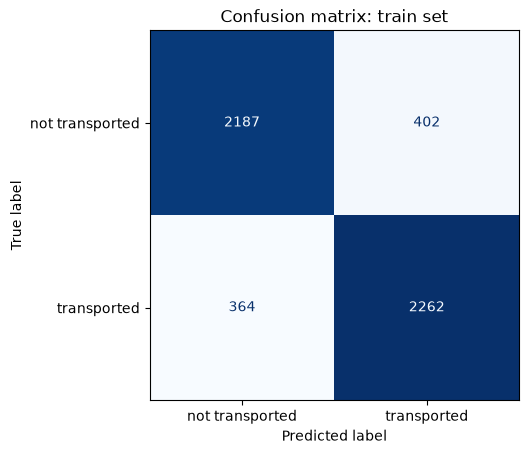

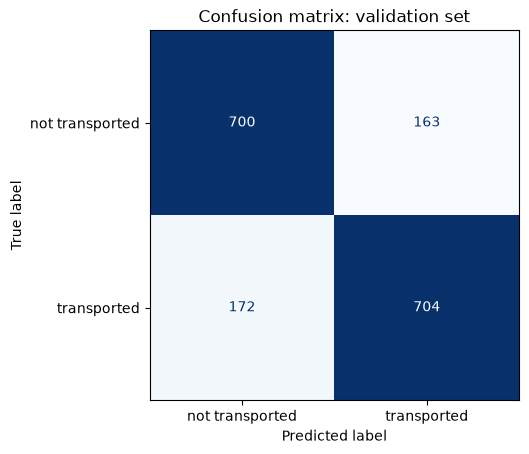

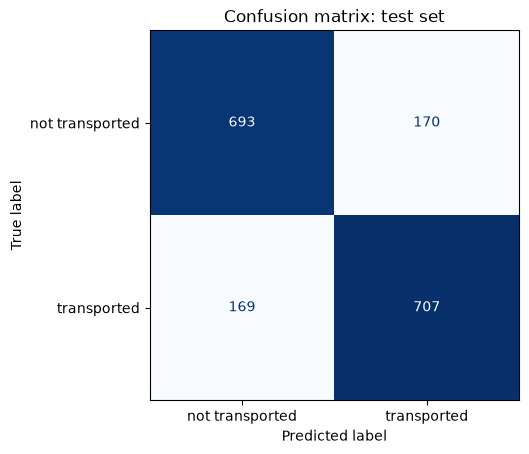

,TN,FP,FN,TP,accuracy,error_rate,precision,recall,sensitivity,specificity,f1
train,2187.0,402.0,364.0,2262.0,0.8531,0.1469,0.8491,0.8614,0.8614,0.8447,0.8552
validation,700.0,163.0,172.0,704.0,0.8074,0.1926,0.8120,0.8037,0.8037,0.8111,0.8078
test,693.0,170.0,169.0,707.0,0.8051,0.1949,0.8062,0.8071,0.8071,0.8030,0.8066


In [3]:
data_sets = {
    "train": (X_train_cb, y_train),
    "validation": (X_val_cb, y_val),
    "test": (X_test_cb, y_test),
}
class_names = [f"not {target}", target]

results = {}
for set_name, (X, y) in data_sets.items():
    matrix = get_confusion_matrix(X, y)
    plot_confusion_matrix(matrix, set_name, class_names)
    results[set_name] = calculate_metrics(matrix)

pd.DataFrame(results).T.round(4)